<a href="https://colab.research.google.com/github/MarceloCoccaro12/Disciplina_de_Inteligencia_Artificial_UMC/blob/main/housing_california.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importando as Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, classification_report
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Carregar o dataset
https://www.kaggle.com/datasets/kathuman/housing

In [2]:
!kaggle datasets download -d kathuman/housing --unzip -p /content/dados

Dataset URL: https://www.kaggle.com/datasets/kathuman/housing
License(s): CC0-1.0
100% 400k/400k [00:00<00:00, 77.5MB/s]



In [3]:
housing_df = pd.read_csv("/content/dados/housing.csv")

In [4]:
housing_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# Quantidade de Linhas e Colunas

In [5]:
housing_df.shape

(20640, 10)

# Tipos de Dados

In [6]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


# Estatísticas descritivas

In [7]:
housing_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## Quais variáveis possuem maior dispersão?



## Quais apresentam valores muito altos?



## Existem valores mínimos ou máximos aparentemente estranhos?



## Quais variáveis parecem ter relação com o preço?

* `median_income` (Renda Média): É a variável com maior relação direta e positiva. Zonas com rendimentos familiares mais elevados apresentam valores de imóveis significativamente mais altos.

* `ocean_proximity` e Coordenadas Geográficas (`latitude` / `longitude`): A localização geográfica influencia fortemente o valor. Imóveis situados perto do mar (OCEAN, NEAR BAY, NEAR OCEAN) registam valores médios substancialmente superiores aos situados no interior (INLAND).

* `housing_median_age` (Idade do Imóvel): Mostra uma ligeira relação positiva, dado que zonas urbanas consolidadas e históricas no litoral tendem a valorizar mais do que áreas mais recentes no interior.

# Valores Ausentes

In [8]:
housing_df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


# Análise exploratora

## Distribuição da variável alvo
Apresentando um histograma da variável que será utilizada como Preço do Imóvel.

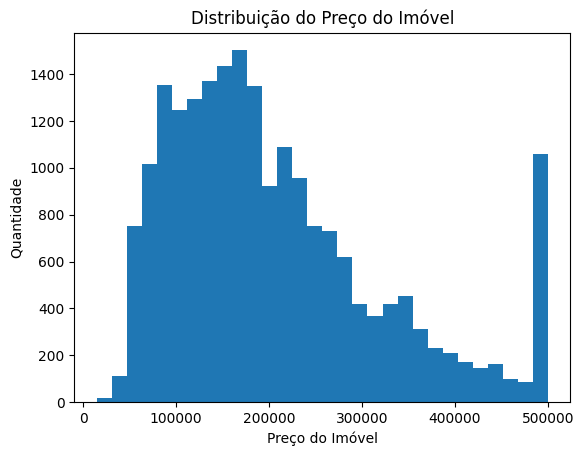

In [9]:
plt.hist(housing_df['median_house_value'], bins=30)
plt.xlabel("Preço do Imóvel")
plt.ylabel("Quantidade")
plt.title("Distribuição do Preço do Imóvel")
plt.show()

## Boxplot
Criando boxplot para identificar possíveis valores extremos de Preço do Imóvel.

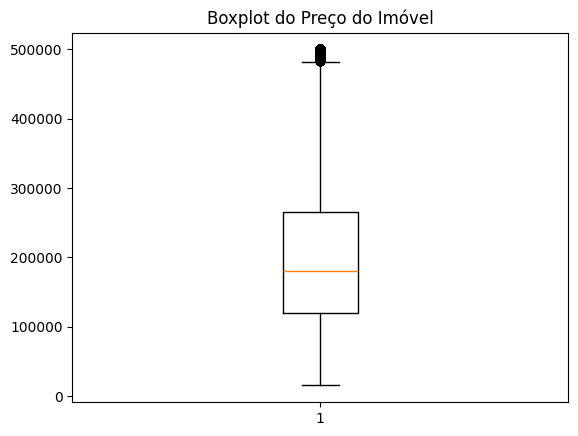

In [10]:
plt.boxplot(housing_df['median_house_value'].dropna())
plt.title("Boxplot do Preço do Imóvel")
plt.show()

Criando boxplots para identificar possíveis valores extremos de População (Moradores)

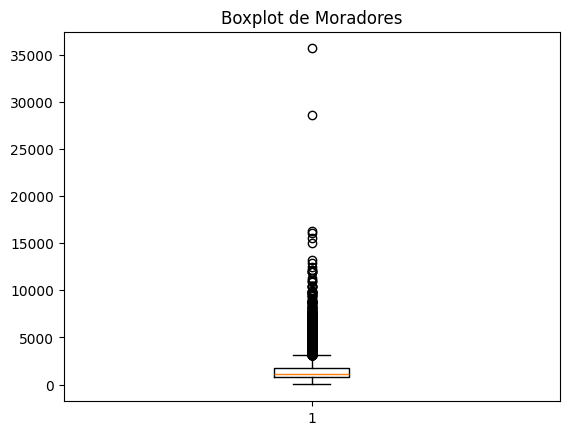

In [11]:
plt.boxplot(housing_df['population'].dropna())
plt.title("Boxplot de Moradores")
plt.show()

Criando boxplot para identificar possíveis valores extremos de Renda Média.

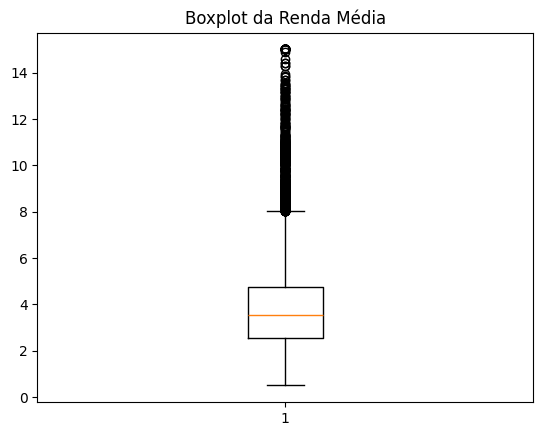

In [12]:
plt.boxplot(housing_df['median_income'].dropna())
plt.title("Boxplot da Renda Média")
plt.show()

## Correlação

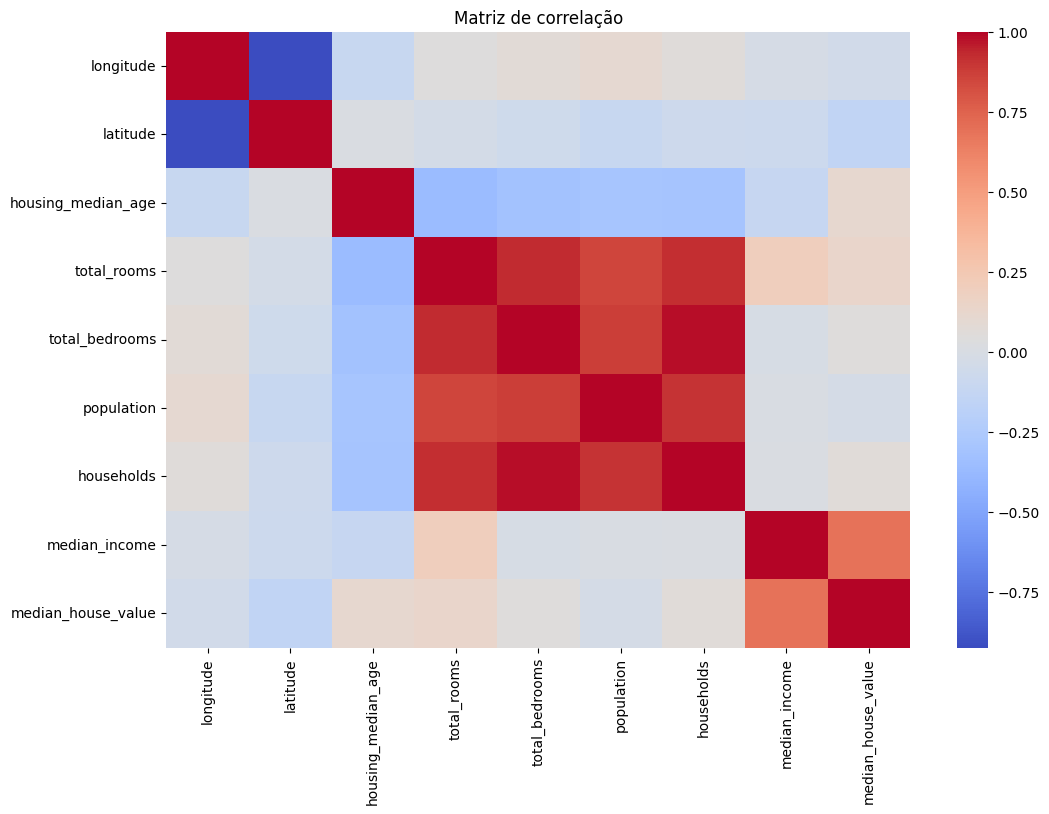

In [13]:
plt.figure(figsize=(12, 8))
sns.heatmap(housing_df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Matriz de correlação")
plt.show()

### Variáveis mais correlacionadas com o preço (`median_house_value`)

* `median_income`:
  * Correlação: +62,5
  * Quanto maior a renda media das famílias, maior tende ser o preço das casas

### Variáveis pouco relacionadas com Preço (`median_house_value`)

* `population`: -0,02 (praticamente nenhuma relação linear direta com o preço).   
* `longitude`: -0,05   
* `total_bedrooms`: +0,05  
* `households`: +0,07   
* `housing_median_age`: +0,11   
* `total_rooms`: +0,13   

* Têm pouca relação direta com o preço porque medem o tamanho absoluto do bloco, e não o tamanho de cada imóvel

### Possíveis Variáveis Redundantes

* `households` vs. `total_bedrooms`: +0,98
* `total_rooms` vs. `total_bedrooms`: +0,93
* `households` vs. `total_rooms`: +0,92
* `population` vs. `households`: +0,91
* `longitude` vs. `latitude`: -0,92

# Treino e teste (Dados Originais, Removendo Linhas e Imputando a Mediana)

## Dados Originais

In [14]:
X = housing_df.drop('median_house_value', axis=1) # as características (features)
y = housing_df['median_house_value'] # os rótulos (classe)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
numerical_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
categorical_features = ['ocean_proximity']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', SVR(kernel='linear'))])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor', SVR(kernel='linear'))])

In [17]:
# y_pred =  model.predict(X_test)

In [18]:
# r2 = r2_score(y_test, y_pred)
# print(f"R²: {r2 :.2f}")

### Justificativa do erro

Ele da um erro pois existem células com valores Nan (nulos), não sendo possível realizar o treinamento e teste, sendo necessario realizar o tratamento desses dados (removendo linhas ou imputando a mediana).

## Linhas removidas

In [19]:
housing_remove_rows = housing_df.dropna()

In [20]:
housing_remove_rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### Preparação dos Dados

In [21]:
X = housing_remove_rows.drop('median_house_value', axis=1) # as características (features)
y = housing_remove_rows['median_house_value'] # os rótulos (classe)

In [22]:
pd.get_dummies(X['ocean_proximity'])

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,False,False,False,True,False
1,False,False,False,True,False
2,False,False,False,True,False
3,False,False,False,True,False
4,False,False,False,True,False
...,...,...,...,...,...
20635,False,True,False,False,False
20636,False,True,False,False,False
20637,False,True,False,False,False
20638,False,True,False,False,False


### Separação entre treino e teste

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
numerical_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
categorical_features = ['ocean_proximity']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', SVR(kernel='linear'))])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor', SVR(kernel='linear'))])

In [25]:
y_pred =  model.predict(X_test)

In [26]:
mae = mean_absolute_error(y_test, y_pred)
print(f"Erro médio absoluto, removendo as linhas: {mae :.2f}")

Erro médio absoluto, removendo as linhas: 83838.94


In [27]:
r2 = r2_score(y_test, y_pred)
print(f"R² removendo linhas: {r2 :.2f}")

R² removendo linhas: 0.07


## Imputação pela Mediana Coluna `total_bedrooms`

Neste caso, utilizaremos a Media na coluna para preencher celulas vazias/nulas.

In [28]:
housing_mediana = housing_df.copy()

In [29]:
mediana_bedrooms = housing_mediana['total_bedrooms'].median()
housing_mediana['total_bedrooms'].fillna(mediana_bedrooms, inplace=True)

/tmp/ipykernel_2491/3637043881.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  housing_mediana['total_bedrooms'].fillna(mediana_bedrooms, inplace=True)


In [30]:
housing_mediana.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


### Preparação dos Dados

In [31]:
X = housing_mediana.drop('median_house_value', axis=1) # as características (features)
y = housing_mediana['median_house_value'] # os rótulos (classe)

### Separação entre treino e teste

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
numerical_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
categorical_features = ['ocean_proximity']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', SVR(kernel='linear'))])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor', SVR(kernel='linear'))])

In [34]:
y_pred = model.predict(X_test)

In [35]:
mae = mean_absolute_error(y_test, y_pred)
print(f"Erro médio absoluto com mediana imputada: {mae :.2f}")

Erro médio absoluto com mediana imputada: 81290.97


In [36]:
r2 = r2_score(y_test, y_pred)
print(f"R² com mediana imputada: {r2 :.2f}")

R² com mediana imputada: 0.07


# Definição da Abordagem de Imputação

Após realizar o tratamento dos dados, obtendo $R^2 = 0{,}07$ tanto ao imputar a mediana nos valores vazios quanto ao remover as linhas (ambas com o kernel linear), foi escolhida a mediana para continuar a análise. Essa opção evitou a perda de dados, mantendo a integridade da base inicial.

# Identificação de Outliners
* Para cada variável analisada, informe:

  *  Quantidade de outliers encontrados;

  * Percentual de outliers;

  * Valores mínimos e máximos;

  * Método utilizado para identificação.

## Váriavel: `longitude`



In [37]:
col = housing_mediana['longitude']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: -124.35
Valor Máximo: -114.31
Limite Inferior: -127.48 | Limite Superior: -112.33
Quantidade de Outliers: 0
Percentual de Outliers: 0.00%


* Resultado:
  * Valor Mínimo: -124,35
  *  Valor Máximo: -114,31
  *  Limites Calculados: Inferior = -127,48 | Superior = -112,33
  *  Quantidade de Outliers: 0
  * Percentual de Outliers: 0,00%
  * Método Utilizado: IQR (Q3 - Q1)

## Váriavel: `latitude`


In [38]:
col = housing_mediana['latitude']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 32.54
Valor Máximo: 41.95
Limite Inferior: 28.26 | Limite Superior: 43.38
Quantidade de Outliers: 0
Percentual de Outliers: 0.00%


* Resultado:
  * Valor Mínimo: 32,54
  *  Valor Máximo: 41,95
  *  Limites Calculados: Inferior = 28,26 | Superior = 43,38
  *  Quantidade de Outliers: 0
  * Percentual de Outliers: 0,00%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `housing_median_age`


In [39]:
col = housing_mediana['housing_median_age']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 1.0
Valor Máximo: 52.0
Limite Inferior: -10.50 | Limite Superior: 65.50
Quantidade de Outliers: 0
Percentual de Outliers: 0.00%


* Resultado:
  * Valor Mínimo: 1,00
  *  Valor Máximo: 52,00
  *  Limites Calculados: Inferior = -10,50 | Superior = 65,50
  *  Quantidade de Outliers: 0
  * Percentual de Outliers: 0,00%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `total_rooms`


In [40]:
col = housing_mediana['total_rooms']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 2.0
Valor Máximo: 39320.0
Limite Inferior: -1102.62 | Limite Superior: 5698.38
Quantidade de Outliers: 1287
Percentual de Outliers: 6.24%


* Resultado:
  * Valor Mínimo: 2,00
  *  Valor Máximo: 39320,00
  *  Limites Calculados: Inferior = -1102,62 | Superior = 5698,38
  *  Quantidade de Outliers: 1287
  * Percentual de Outliers: 6.24%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `total_bedrooms`


In [41]:
col = housing_mediana['total_bedrooms']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 1.0
Valor Máximo: 6445.0
Limite Inferior: -222.38 | Limite Superior: 1162.62
Quantidade de Outliers: 1306
Percentual de Outliers: 6.33%


* Resultado:
  * Valor Mínimo: 1,00
  * Valor Máximo: 6445,00
  * Limites Calculados: Inferior = -222,38 | Superior = 1162,62
  * Quantidade de Outliers: 1306
  * Percentual de Outliers: 6.33%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `population`


In [42]:
col = housing_mediana['population']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 3.0
Valor Máximo: 35682.0
Limite Inferior: -620.00 | Limite Superior: 3132.00
Quantidade de Outliers: 1196
Percentual de Outliers: 5.79%


* Resultado:
  * Valor Mínimo: 3,00
  * Valor Máximo: 35682,00
  * Limites Calculados: Inferior = -620,00 | Superior = 3132,00
  * Quantidade de Outliers: 1196
  * Percentual de Outliers: 5.79%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `households`


In [43]:
col = housing_mediana['households']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 1.0
Valor Máximo: 6082.0
Limite Inferior: -207.50 | Limite Superior: 1092.50
Quantidade de Outliers: 1220
Percentual de Outliers: 5.91%


* Resultado:
  * Valor Mínimo: 1,00
  * Valor Máximo: 6082,00
  * Limites Calculados: Inferior = -207,50 | Superior = 1092,50
  * Quantidade de Outliers: 1220
  * Percentual de Outliers: 5.91%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `median_income`





In [44]:
col = housing_mediana['median_income']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 0.4999
Valor Máximo: 15.0001
Limite Inferior: -0.71 | Limite Superior: 8.01
Quantidade de Outliers: 681
Percentual de Outliers: 3.30%


* Resultado:
  * Valor Mínimo: 0,4999
  * Valor Máximo: 15,0001
  * Limites Calculados: Inferior = -0,71 | Superior = 8,01
  * Quantidade de Outliers: 681
  * Percentual de Outliers: 3.30%
  * Método Utilizado: IQR (Q3 - Q1)

## Variável: `median_house_value`





In [45]:
col = housing_mediana['median_house_value']
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR =  Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = col[(col < limite_inferior) | (col > limite_superior)]

print(f"Valor Mínimo: {col.min()}")
print(f"Valor Máximo: {col.max()}")
print(f"Limite Inferior: {limite_inferior:.2f} | Limite Superior: {limite_superior:.2f}")
print(f"Quantidade de Outliers: {len(outliers)}")
print(f"Percentual de Outliers: {(len(outliers)/len(col))*100:.2f}%")

Valor Mínimo: 14999.0
Valor Máximo: 500001.0
Limite Inferior: -98087.50 | Limite Superior: 482412.50
Quantidade de Outliers: 1071
Percentual de Outliers: 5.19%


* Resultado:
  * Valor Mínimo: 14999,00
  * Valor Máximo: 500001,00
  * Limites Calculados: Inferior = -98087,50 | Superior = 482412,50
  * Quantidade de Outliers: 1071
  * Percentual de Outliers: 5.19%
  * Método Utilizado: IQR (Q3 - Q1)

## Tratamento dos Outliers

In [46]:
housing_capping = housing_mediana.copy()

In [47]:
housing_capping.shape

(20640, 10)

In [48]:
housing_capping.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [49]:
colunas = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

for col in colunas:
  Q1 = housing_capping[col].quantile(0.25)
  Q3 = housing_capping[col].quantile(0.75)
  IQR = Q3 - Q1
  limite_superior = Q3 + 1.5 * IQR
  limite_inferior = Q1 - 1.5 * IQR

  outliers = housing_capping[(housing_capping[col] < limite_inferior) | (housing_capping[col] > limite_superior)]

  # Ajusta os limites sem remover nenhuma linha
  housing_capping[col] = housing_capping[col].clip(lower=limite_inferior, upper=limite_superior)
  print(f"Quantidade de Outliers {col}: {len(outliers)}")


Quantidade de Outliers total_rooms: 1287
Quantidade de Outliers total_bedrooms: 1306
Quantidade de Outliers population: 1196
Quantidade de Outliers households: 1220
Quantidade de Outliers median_income: 681
Quantidade de Outliers median_house_value: 1071


## Preparação dos Dados

In [50]:
X = housing_capping.drop('median_house_value', axis=1)
y = housing_capping['median_house_value']

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [52]:
numerical_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
categorical_features = ['ocean_proximity']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('regressor', SVR(kernel='rbf', C=10000.0, epsilon=0.1))])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor', SVR(C=10000.0))])

In [53]:
y_pred = model.predict(X_test)

In [54]:
mae = mean_absolute_error(y_test, y_pred)
print(f"Erro medio absoluto com remoção dos outliners: {mae:.2f}")

Erro medio absoluto com remoção dos outliners: 40237.56


In [55]:
r2 =r2_score(y_test, y_pred)
print(f"R² com remoção de outliers: {r2 :.2f}")

R² com remoção de outliers: 0.72


In [56]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(rmse)

59801.48718026473


In [58]:
param_grid = {
    'regressor__C': [0.1, 1, 10, 100],
    'regressor__gamma': ['scale', 'auto', 0.1, 1],
    'regressor__kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}


print("Iniciando a otimização de hiperparâmetros com GridSearchCV...")
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='r2', verbose=2, n_jobs=-1)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"\n--- Resultados da Otimização de Hiperparâmetros ---")
print(f"Melhores parâmetros encontrados: {best_params}")
print(f"Melhor R-quadrado (Média da Validação Cruzada): {best_score:.2f}")

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))

print(f"MAE do modelo otimizado no conjunto de teste: {mae_tuned:.2f}")
print(f"R-quadrado do modelo otimizado no conjunto de teste: {r2_tuned:.2f}")


Iniciando a otimização de hiperparâmetros com GridSearchCV...
Fitting 5 folds for each of 64 candidates, totalling 320 fits

--- Resultados da Otimização de Hiperparâmetros ---
Melhores parâmetros encontrados: {'regressor__C': 100, 'regressor__gamma': 1, 'regressor__kernel': 'poly'}
Melhor R-quadrado (Média da Validação Cruzada): 0.71
MAE do modelo otimizado no conjunto de teste: 41319.55
R-quadrado do modelo otimizado no conjunto de teste: 0.69


# Plotando Gráfico Real x Predito

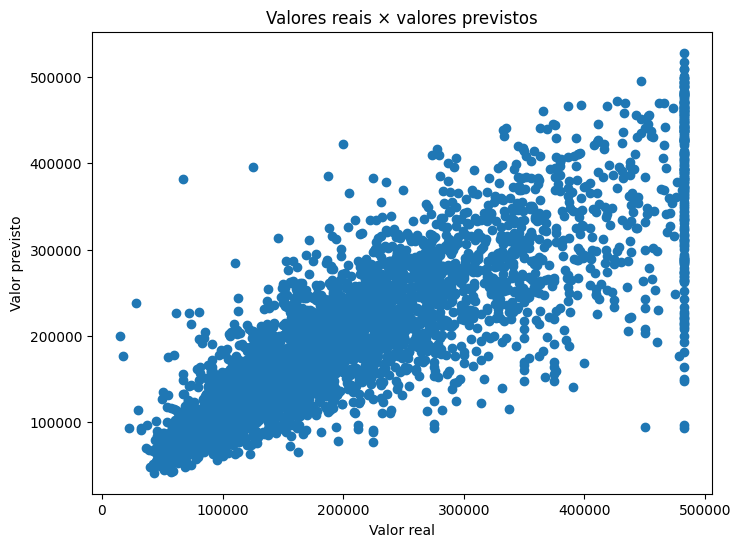

In [59]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Valor real")
plt.ylabel("Valor previsto")
plt.title("Valores reais × valores previstos")
plt.show()